In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 02 — One requirement: what does a contract do to the weights? (Phase A)

**The question of `grum_formalization.md` §2.5, "the single most important open question":** if we know what
`ram=8GB` does, can we predict what `ram=16GB` or `ram=4GB` does? Or does every level need its own run?
Until now every feature had been asked at one level only. **Phase A has since landed**: the 8 qwen and gemma models
have all 6 levels (13/14/16-inch, 4/8/16GB). This notebook uses them. OLMo has only 14-inch and 8GB and joins where
it can.

### The model, in words
A one-requirement contract "*I prefer level ℓ of feature f*" can do three things to the weights (notebook 01):

| | what | symbol |
|---|---|---|
| 1 | **push** the requested level up | ρ (rho) |
| 2 | **flatten the model's old taste** on the same feature | σ (sigma), 0 = kept, 1 = gone |
| 3 | **flatten the other features** (leakage) | κ (kappa), 0 = kept, 1 = gone, > 1 = reversed |

$$w_f = (1-\sigma_f)\,a_f + \rho_f\, e_\ell \qquad\qquad w_g = (1-\kappa_{f\to g})\,a_g \;\;(g \neq f)$$

*a* = the weights with no contract, *e*ℓ = the shape of the push (centred). Two shapes are compared in section 3b:
**peak** (+1 on level ℓ only) and **ideal point** (minus the distance from ℓ: asking for 13-inch also puts 14-inch
above 16-inch). The bet of the structured GRUM: **σ, ρ and κ belong to the feature, not to the level** (one number for
"a RAM request", whatever level it names).

In [2]:
from grumish import *
import matplotlib.pyplot as plt
setup_plots()
FIG = "figs/GRUMish"; os.makedirs(FIG, exist_ok=True)
R = load_all()
QG = [m for m in REAL if FAMILY[m] != "olmo"]          # the 7 models with all 6 levels
SPEC = ["screen", "ram"]
print("models with all 6 levels:", QG)

models with all 6 levels: ['qwen-7B', 'qwen-32B', 'qwen-72B', 'gemma-1B', 'gemma-4B', 'gemma-12B', 'gemma-27B']


## 1. One model, all six requests

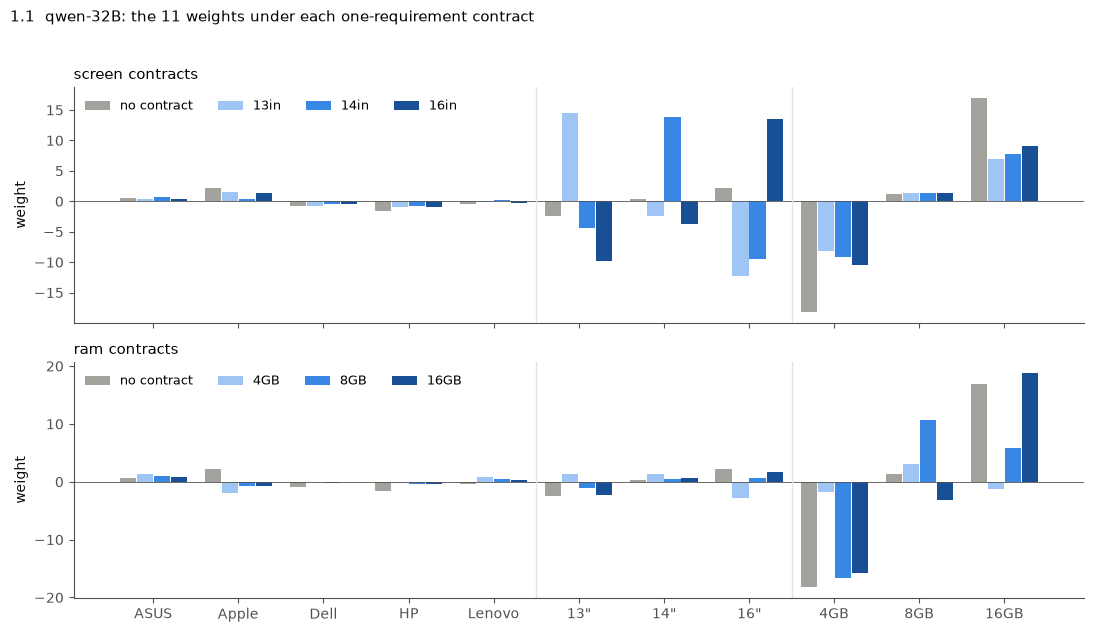

In [3]:
m = "qwen-32B"
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
x = np.arange(len(LV))
for ax, f in zip(axes, SPEC):
    cons = ["none"] + [f"{f}={l}" for l in LEVELS[f]]
    cols = [GRAY, "#9ec5f4", "#3987e5", "#184f95"]
    for k, (c, col) in enumerate(zip(cons, cols)):
        ax.bar(x + (k - 1.5) * 0.2, R[(m, c)].w.values, 0.19, color=col, label=short(c) if c != "none" else "no contract")
    ax.axhline(0, color=INK2, lw=0.6)
    for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1)
    ax.legend(frameon=False, ncol=4, fontsize=9, loc="upper left"); ax.set_ylabel("weight")
    ax.set_title(f"{f} contracts", loc="left")
axes[1].set_xticks(x, [l.replace("-inch", '"') for _, l in LV])
fig.suptitle(f"1.1  {m}: the 11 weights under each one-requirement contract", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.96)); fig.savefig(f"{FIG}/02_1_example.png", dpi=150); plt.show()

- **Each screen request lifts its own size to the top**, and `8GB` and `16GB` become the best RAM. `4GB` does not make it
  (qwen-32B ranks 8GB > 16GB > 4GB): the model pays only part of the price.
- **Apple falls from the top to the bottom under every RAM request.** That is more than a flattening of the brand taste:
  section 4 measures it, and notebook 05 §2 shows where it comes from (an Apple that misses the request is punished
  more than another brand that misses it).

## 2. The requested level: a push, or a target?

**m0** = how far the requested level is ahead of the best other level **before** the contract (negative = the model
did not want it). **m1** = the same **after**. Two pure cases:
- **push** — the contract adds a fixed amount: m1 = m0 + const, points on a line of slope 1;
- **target** — the contract puts the level on top by a fixed margin, whatever the start: slope 0.

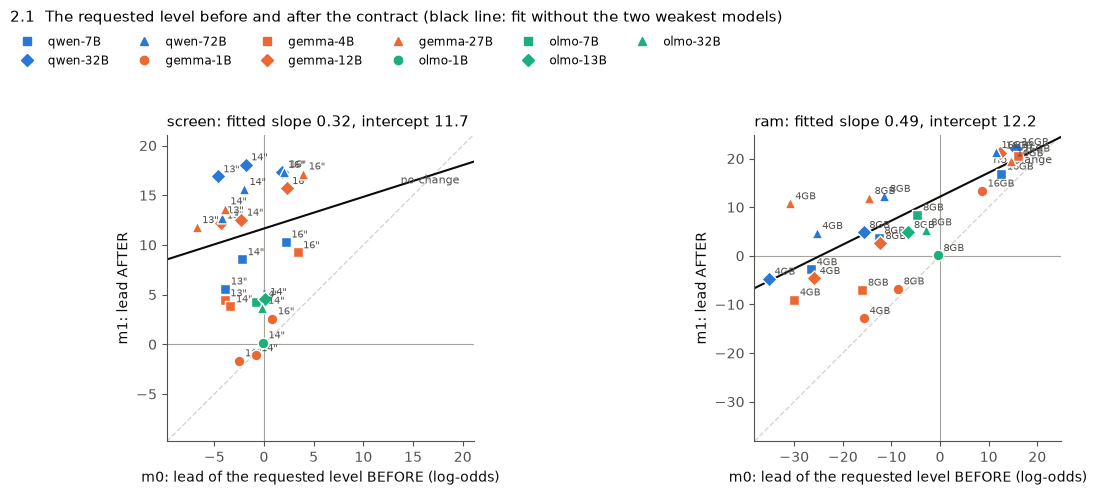

{'screen': (np.float64(0.32), np.float64(11.65)), 'ram': (np.float64(0.49), np.float64(12.16))}
f           ram              screen                
l          16GB   4GB   8GB 13-inch 14-inch 16-inch
model                                              
qwen-7B    16.9  -2.8   3.7     5.6     8.5    10.3
qwen-32B   21.9  -4.7   4.9    16.9    18.1    17.3
qwen-72B   21.3   4.7  12.3    12.8    15.6    17.4
gemma-1B   13.4 -12.8  -6.8    -1.6    -1.1     2.6
gemma-4B   20.6  -9.0  -7.0     4.4     3.8     9.2
gemma-12B  21.2  -4.6   2.6    12.2    12.5    15.7
gemma-27B  19.6  10.8  11.9    11.8    13.7    17.2
olmo-1B     NaN   NaN   0.1     NaN     0.2     NaN
olmo-7B     NaN   NaN   8.5     NaN     4.3     NaN
olmo-13B    NaN   NaN   4.9     NaN     4.5     NaN
olmo-32B    NaN   NaN   5.4     NaN     3.7     NaN


In [4]:
rows = []
for (m, c), r in R.items():
    p = parse(c)
    if len(p) != 1 or m == "qwen-0.5B" or list(p)[0] not in SPEC: continue
    (f, l), = p.items(); a, w = R[(m, "none")].w[f], r.w[f]
    rows.append(dict(model=m, f=f, l=l, m0=a[l] - a.drop(l).max(), m1=w[l] - w.drop(l).max()))
M = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
FIT = {}
for ax, f in zip(axes, SPEC):
    s = M[M.f == f]
    lim = (min(s.m0.min(), s.m1.min()) - 3, max(s.m0.max(), s.m1.max()) + 3)
    ax.plot(lim, lim, color=LGRAY, lw=1, ls="--"); ax.text(lim[1] - 1, lim[1] - 4, "no change ", fontsize=8, color=INK2, va="top", ha="right")
    ax.axhline(0, color=GRAY, lw=0.8); ax.axvline(0, color=GRAY, lw=0.8)
    for _, r in s.iterrows():
        st = model_style(r.model)
        ax.scatter(r.m0, r.m1, s=60, color=st["color"], marker=st["marker"], edgecolor="white", linewidth=1, zorder=3)
        ax.annotate(r.l.replace("-inch", '"'), (r.m0, r.m1), xytext=(4, 3), textcoords="offset points", fontsize=7, color=INK2)
    big = s[s.model.isin(["qwen-7B", "qwen-32B", "qwen-72B", "gemma-4B", "gemma-12B", "gemma-27B", "olmo-7B", "olmo-13B", "olmo-32B"])]
    b, a0 = np.polyfit(big.m0, big.m1, 1); FIT[f] = (b, a0)
    xx = np.array(lim); ax.plot(xx, a0 + b * xx, color=INK, lw=1.5)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel("m0: lead of the requested level BEFORE (log-odds)"); ax.set_ylabel("m1: lead AFTER")
    ax.set_title(f"{f}: fitted slope {b:.2f}, intercept {a0:.1f}", loc="left")
handles = [plt.Line2D([], [], ls="", marker=model_style(m)["marker"], color=model_style(m)["color"], label=m) for m in REAL]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, 0.95), ncol=6, frameon=False, fontsize=8.5)
fig.suptitle("2.1  The requested level before and after the contract (black line: fit without the two weakest models)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/02_2_push_or_target.png", dpi=150); plt.show()
print({f: tuple(round(v, 2) for v in FIT[f]) for f in FIT})
print(M.pivot_table(index="model", columns=["f", "l"], values="m1").loc[[m for m in REAL if m in M.model.values]].round(1).to_string())

- **Screen is close to a target.** After the contract the requested screen leads by about 12–18 log-odds in the big
  models, whatever the start: fitted slope **0.32** (intercept 11.7).
- **RAM is half push, half target**: slope **0.49**. The old taste still counts. `16GB` (already loved) ends at
  +13 … +22, `4GB` (hated) at −13 … +11. `4GB` still loses in 5 of 7 qwen/gemma models (all but qwen-72B and gemma-27B).
- **The weak models do not follow the pattern**: gemma-1B sits near the "no change" diagonal; OLMo reacts mildly.

## 3. One push and one flattening per feature, for all levels?

Section 2 measured the requested level only. Now the whole feature: fit **one** σ and **one** ρ per model and feature
(ideal-point shape, section 3b)
on all 3 levels together, and check how well this single pair describes the three runs (R² of the feature's weights).

Why not one ρ, σ per level? For the extreme levels the old taste *a* and the push *e*ℓ point almost the same way
(13-inch is the least liked, so "push 13-inch up" ≈ "flatten the old taste"). One run cannot separate them; three
levels together can.

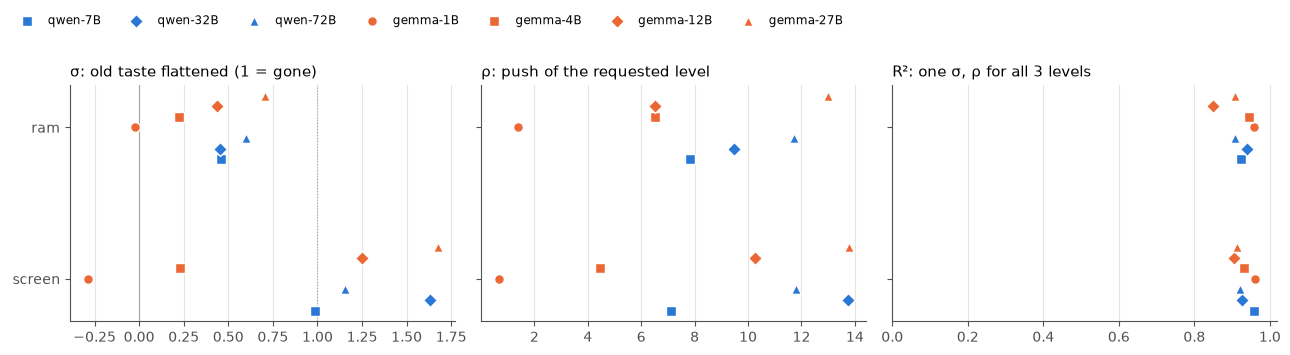

                  sigma    rho    r2
f      model                        
screen qwen-7B     0.99   7.13  0.96
ram    qwen-7B     0.46   7.82  0.92
screen qwen-32B    1.63  13.73  0.93
ram    qwen-32B    0.45   9.47  0.94
screen qwen-72B    1.16  11.79  0.92
ram    qwen-72B    0.60  11.71  0.91
screen gemma-1B   -0.29   0.66  0.96
ram    gemma-1B   -0.02   1.38  0.96
screen gemma-4B    0.23   4.45  0.93
ram    gemma-4B    0.23   6.50  0.94
screen gemma-12B   1.25  10.28  0.91
ram    gemma-12B   0.43   6.53  0.85
screen gemma-27B   1.67  13.77  0.91
ram    gemma-27B   0.71  13.00  0.91


In [5]:
rows, K = [], []
for m in REAL:
    a = R[(m, "none")].w
    for f in SPEC:
        tr = [(f, l, R[(m, f"{f}={l}")].w) for l in LEVELS[f] if (m, f"{f}={l}") in R]
        for f2, l, w in tr:                                   # one-run kappas, for section 4
            P1 = fit_struct(a, [(f2, l, w)], True)
            K.append(dict(model=m, f=f, l=l, **{f"kappa_{g}": P1["kappa"][(f, g)] for g in FEATS if g != f}))
        if len(tr) < 3: continue
        P = fit_struct(a, tr, True)
        obs = np.concatenate([w[f].values for _, _, w in tr])
        pred = np.concatenate([predict_struct(a, P, {f: l})[f].values for _, l, _ in tr])
        rows.append(dict(model=m, f=f, sigma=P["sigma"][f], rho=P["rho"][f], r2=r2(pred, obs)))
PS = pd.DataFrame(rows); K = pd.DataFrame(K)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (col, lab) in zip(axes, [("sigma", "σ: old taste flattened (1 = gone)"), ("rho", "ρ: push of the requested level"),
                                 ("r2", "R²: one σ, ρ for all 3 levels")]):
    for i, f in enumerate(SPEC):
        for m in QG:
            v = PS[(PS.model == m) & (PS.f == f)][col].iloc[0]; st = model_style(m)
            ax.scatter(v, i + (QG.index(m) - 3) * 0.07, s=50, color=st["color"], marker=st["marker"], edgecolor="white", zorder=3, label=m if i == 0 else None)
    if col == "sigma": ax.axvline(1, color=GRAY, lw=0.8, ls=":"); ax.axvline(0, color=GRAY, lw=0.8)
    if col == "r2": ax.set_xlim(0, 1.02)
    ax.set_yticks(range(2), SPEC); ax.set_title(lab, loc="left"); ax.grid(axis="x", color=GRID, lw=0.8)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.99), ncol=7, frameon=False, fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/02_3_rho_sigma.png", dpi=150); plt.show()
print(PS.set_index(["f", "model"]).round(2).to_string())

- **One σ and one ρ per feature describe all three levels well**: R² 0.85–0.96 in all 7 models. So the shift caused by
  a request belongs to the **feature**, not the level — the bet the structured GRUM needs.
- **Screen: σ ≥ 1** (0.99–1.67 in qwen-7/32/72B and gemma-12/27B). A screen request **erases** the old screen taste — in
  some models even turns it — and replaces it with the push toward the requested size. σ above 1 and the ideal-point
  push are partly the same thing (both lower 16-inch under a 13-inch request), so read σ and ρ together, not apart.
- **RAM: σ ≈ 0.4–0.7.** A RAM request erases only about half of the old RAM taste. That is why `4GB` fails (section 2).
- gemma-1B (σ ≈ 0, ρ ≈ 1) does not react; gemma-4B is in between (σ 0.23).

## 3b. Peak or ideal point?

Look at the order of the three levels **after** an extreme request. A "peak" push lifts only the requested level, so
the other two keep the model's old order (or tie, if the old taste is gone). An **ideal point** ranks by distance from
the request: after "13-inch" comes 14-inch, then 16-inch — the old taste turned upside down.

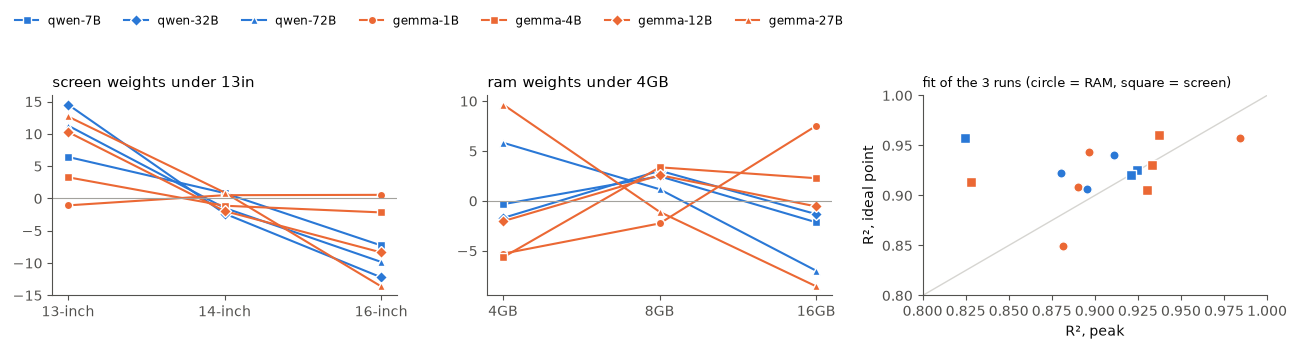

shape             ideal  peak
f      model                 
ram    gemma-12B   0.85  0.88
       gemma-1B    0.96  0.98
       gemma-27B   0.91  0.89
       gemma-4B    0.94  0.90
       qwen-32B    0.94  0.91
       qwen-72B    0.91  0.90
       qwen-7B     0.92  0.88
screen gemma-12B   0.91  0.93
       gemma-1B    0.96  0.94
       gemma-27B   0.91  0.83
       gemma-4B    0.93  0.93
       qwen-32B    0.93  0.92
       qwen-72B    0.92  0.92
       qwen-7B     0.96  0.82
shape   ideal   peak
f                   
ram     0.918  0.906
screen  0.931  0.900


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes[:2], ["screen=13-inch", "ram=4GB"]):
    f = list(parse(c))[0]
    for m in QG:
        st = model_style(m)
        ax.plot(range(3), R[(m, c)].w[f].values, color=st["color"], marker=st["marker"], lw=1.5, ms=6, mec="white", label=m)
    ax.axhline(0, color=GRAY, lw=0.8); ax.set_xticks(range(3), LEVELS[f]); ax.set_title(f"{f} weights under {short(c)}", loc="left")
rows = []
for m in QG:
    a = R[(m, "none")].w
    for f in SPEC:
        tr = [(f, l, R[(m, f"{f}={l}")].w) for l in LEVELS[f]]
        obs = np.concatenate([w[f].values for _, _, w in tr])
        for shape in ["peak", "ideal"]:
            P = fit_struct(a, tr, True, shape)
            pred = np.concatenate([predict_struct(a, P, {f: l}, shape=shape)[f].values for _, l, _ in tr])
            rows.append(dict(model=m, f=f, shape=shape, r2=r2(pred, obs)))
SH = pd.DataFrame(rows).pivot_table(index=["f", "model"], columns="shape", values="r2")
ax = axes[2]
for (f, m), r in SH.iterrows():
    st = model_style(m)
    ax.scatter(r["peak"], r["ideal"], s=45, color=st["color"], marker="o" if f == "ram" else "s", edgecolor="white", zorder=3)
ax.plot([0.8, 1], [0.8, 1], color=LGRAY, lw=1); ax.set_xlim(0.8, 1.0); ax.set_ylim(0.8, 1.0)
ax.set_xlabel("R², peak"); ax.set_ylabel("R², ideal point"); ax.set_title("fit of the 3 runs (circle = RAM, square = screen)", loc="left", fontsize=9.5)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 1.0), ncol=7, frameon=False, fontsize=8.5)
fig.suptitle("", y=0.0)
fig.tight_layout(rect=(0, 0, 1, 0.88)); fig.savefig(f"{FIG}/02_3b_ideal_point.png", dpi=150); plt.show()
print(SH.round(2).to_string()); print(SH.groupby(level="f").mean().round(3))

- **After an extreme request the whole ladder turns.** Under `13-inch`, **6 of 7** models rank 13 > 14 > 16 (gemma-1B
  does not react). Under `4GB`, the two that comply rank 4 > 8 > 16 (qwen-72B, gemma-27B); four others put 8GB first —
  they meet the request half way; gemma-1B keeps 16GB.
- **So the request acts as an ideal point**: closer to the requested level is better. "I prefer 4GB" is read as
  "I prefer less RAM", not "4GB and nothing else".
- **The ideal point fits better on average** (R² screen 0.93 vs 0.90, RAM 0.92 vs 0.91); per model it wins for RAM in 5
  of 7 and for screen in 4 of 7 (2 ties). The gain is small, but in the transfer test (section 5) it is the biggest
  step. From here on: ideal point for screen and RAM, peak for brand, which has no order.

## 4. Leakage: does the request flatten the OTHER features — and does that depend on the level?

κ is measured as 1 − (slope of the new weights on the old ones), per other feature. **0** = untouched, **1** =
flattened to nothing, **> 1** = reversed. `grum_formalization.md` §11 had two predictions for this:
- **"naming a feature promotes it above brand"** → κ into brand about the same at every level (ram ≈ 0.94);
- **"it tracks how much the model must give up"** → κ near 0 when the contract agrees with the taste (`16GB`, `16-inch`).

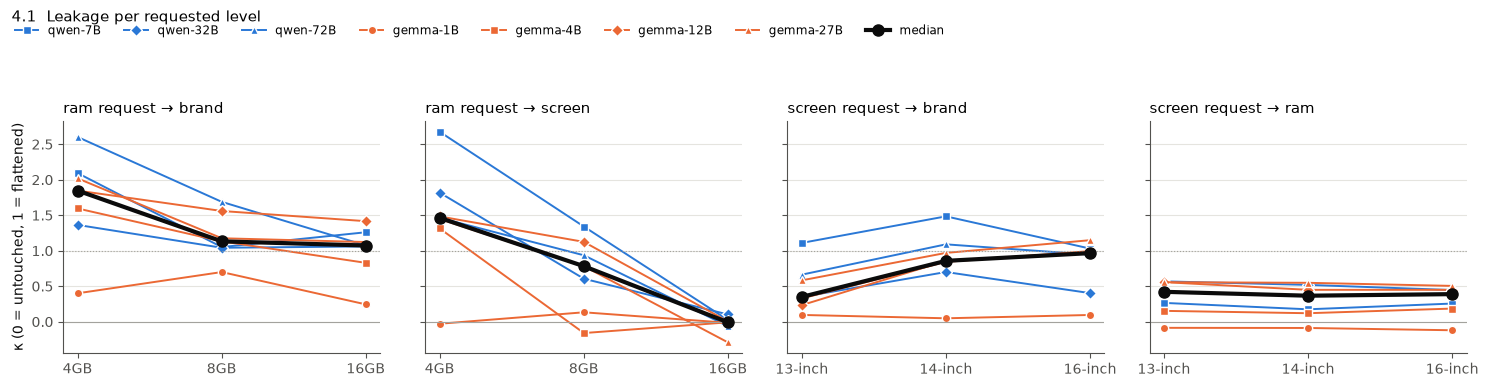

                kappa_brand  kappa_screen  kappa_ram
f      l                                            
ram    16GB            1.07         -0.01        NaN
       4GB             1.85          1.46        NaN
       8GB             1.13          0.78        NaN
screen 13-inch         0.35           NaN       0.42
       14-inch         0.86           NaN       0.37
       16-inch         0.97           NaN       0.39
OLMo (14-inch, 8GB only):
                  kappa_brand  kappa_screen  kappa_ram
model    l                                            
olmo-1B  14-inch         0.14           NaN       0.13
         8GB             0.40         -0.33        NaN
olmo-7B  14-inch         0.06           NaN       0.57
         8GB            -0.34          1.41        NaN
olmo-13B 14-inch         0.01           NaN       0.27
         8GB            -0.35         -0.83        NaN
olmo-32B 14-inch        -0.85           NaN       0.43
         8GB            -1.82          1.39        NaN


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
PAN = [("ram", "brand"), ("ram", "screen"), ("screen", "brand"), ("screen", "ram")]
for ax, (f, g) in zip(axes, PAN):
    for m in QG:
        s = K[(K.model == m) & (K.f == f)].set_index("l").reindex(LEVELS[f])
        st = model_style(m)
        ax.plot(range(3), s[f"kappa_{g}"], color=st["color"], marker=st["marker"], lw=1.4, ms=6, mec="white", label=m)
    med = K[(K.model.isin(QG)) & (K.f == f)].groupby("l")[f"kappa_{g}"].median().reindex(LEVELS[f])
    ax.plot(range(3), med, color=INK, lw=3, marker="o", ms=8, label="median", zorder=5)
    ax.axhline(0, color=GRAY, lw=0.8); ax.axhline(1, color=GRAY, lw=0.8, ls=":")
    ax.set_xticks(range(3), LEVELS[f]); ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_title(f"{f} request → {g}", loc="left")
axes[0].set_ylabel("κ (0 = untouched, 1 = flattened)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.97), ncol=8, frameon=False, fontsize=8.5)
fig.suptitle("4.1  Leakage per requested level", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/02_4_leakage.png", dpi=150); plt.show()
print(K[K.model.isin(QG)].groupby(["f", "l"])[["kappa_brand", "kappa_screen", "kappa_ram"]].median().round(2).to_string())
print("OLMo (14-inch, 8GB only):"); print(K[K.model.str.startswith("olmo")].set_index(["model", "l"])[["kappa_brand", "kappa_screen", "kappa_ram"]].round(2).to_string())

- **RAM → brand: κ > 1 at every level** (median 1.07 `16GB`, 1.13 `8GB`, **1.85 `4GB`**). κ > 1 means the brand order
  **turns**: Apple goes from 1st to 5th in 6 of 7 models under any RAM request. Not a flattening, a reversal — even when
  the request agrees with the taste (`16GB`).
- **Screen → brand: smaller, and growing toward the *liked* level**: 0.35 (13-inch), 0.86 (14), 0.97 (16).
- **RAM → screen tracks the level**: −0.01 (`16GB`), 0.78 (`8GB`), **1.46 (`4GB`)** — the screen taste vanishes or turns
  when the user asks for little RAM (section 4b).
- **Screen → RAM: about 0.4 at every level** (0.37–0.42). Smaller than the other way, but not zero.
- **OLMo** (14-inch, 8GB only) is noisy: brand weights are tiny there (range ≤ 1.9), so κ into brand swings −1.8 … 0.4.
- Caveat: with all-pairs weights, κ mixes two things — a flatter taste and an **interaction** (a laptop that misses the
  request loses its other qualities too). Notebook 05 §2 separates them for brand.

### 4b. When RAM is 4GB, which screen does the model want?

The `ram → screen` panel shows κ above 1 under `4GB`: the screen preference does not just flatten, it turns.

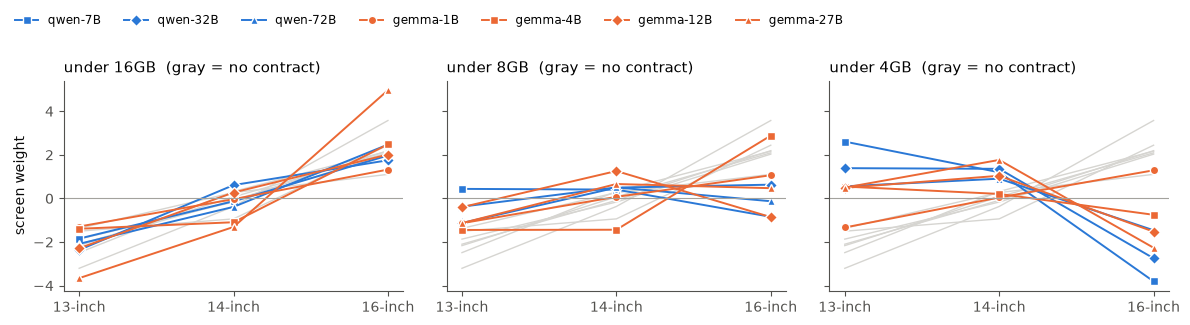

favourite screen: {'none': {'16-inch': 7}, 'ram=16GB': {'16-inch': 7}, 'ram=8GB': {'16-inch': 3, '14-inch': 3, '13-inch': 1}, 'ram=4GB': {'13-inch': 3, '14-inch': 3, '16-inch': 1}}


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
for ax, c in zip(axes, ["ram=16GB", "ram=8GB", "ram=4GB"]):
    for m in QG:
        st = model_style(m)
        ax.plot(range(3), R[(m, c)].w["screen"].values, color=st["color"], marker=st["marker"], lw=1.4, ms=6, mec="white", label=m)
        ax.plot(range(3), R[(m, "none")].w["screen"].values, color=LGRAY, lw=1, zorder=0)
    ax.axhline(0, color=GRAY, lw=0.8); ax.set_xticks(range(3), SCREENS); ax.set_title(f"under {short(c)}  (gray = no contract)", loc="left")
axes[0].set_ylabel("screen weight")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.99), ncol=7, frameon=False, fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/02_4b_screen_under_ram.png", dpi=150); plt.show()
top = {c: pd.Series({m: R[(m, c)].w["screen"].idxmax() for m in QG}).value_counts().to_dict() for c in ["none", "ram=16GB", "ram=8GB", "ram=4GB"]}
print("favourite screen:", top)

- **`16GB` leaves the screen taste alone**: 7 of 7 models still want 16-inch, with almost the same weights.
- **`8GB` and `4GB` take the 16-inch edge away**: the favourite becomes 14-inch or 13-inch in 4 of 7 models (`8GB`) and
  6 of 7 (`4GB`).
- A reading, not a test: a user who asks for little RAM "sounds like" a budget or portable user, and the model adapts
  the screen to it. This is leakage with a **direction of its own** — not just shrinkage of the old taste (κ > 1).

## 5. The real test: predict a level the model never saw

For each model and feature, **hide one level**. Fit σ, ρ, κ on the other two levels, then predict the weights under
the hidden one. Compare four predictions, by **pair accuracy** (share of the 990 laptop pairs where the predicted
utilities pick the model's actual winner):
- **no change** — assume the contract does nothing (w = a);
- **push** — the structured GRUM without self-flattening (σ = 0);
- **push + flatten** — the structured GRUM with the peak shape (σ, ρ, κ);
- **ideal point + flatten** — the same, with the ideal-point shape (section 3b);
- **oracle** — the hidden run's own weights (the best any weight model can do, notebook 01).

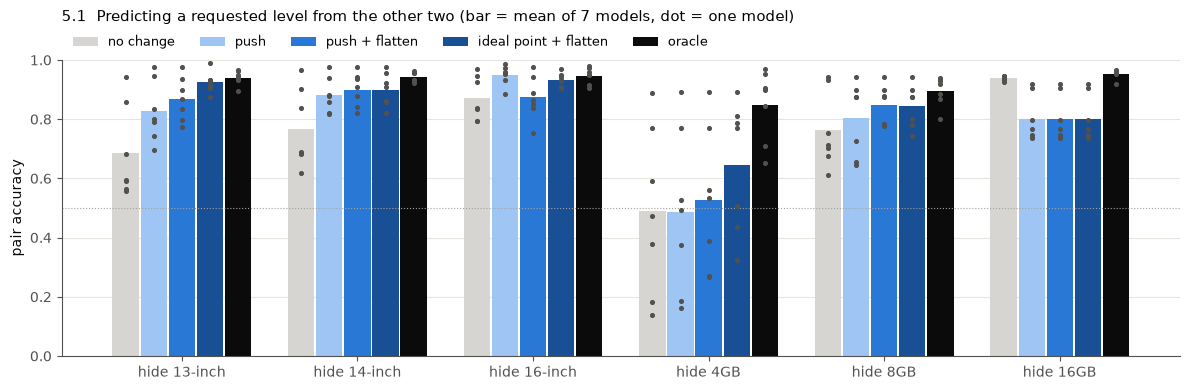

pred            no change   push  push + flatten  ideal point + flatten  oracle
f      l                                                                       
ram    16GB         0.939  0.801           0.801                  0.801   0.953
       4GB          0.489  0.486           0.526                  0.647   0.847
       8GB          0.762  0.802           0.848                  0.844   0.897
screen 13-inch      0.684  0.827           0.869                  0.925   0.941
       14-inch      0.768  0.882           0.900                  0.900   0.942
       16-inch      0.871  0.949           0.873                  0.933   0.947
                         acc    r2w
pred                               
no change              0.752 -1.095
push                   0.791 -0.131
push + flatten         0.803  0.539
ideal point + flatten  0.842  0.705
oracle                 0.921  1.000
without 4GB: {'no change': 0.805, 'push': 0.852, 'push + flatten': 0.858, 'ideal point + flatten': 0.881, 'o

In [9]:
rows = []
for m in QG:
    a = R[(m, "none")].w
    for f in SPEC:
        for l in LEVELS[f]:
            test = R[(m, f"{f}={l}")]
            tr = [(f, k, R[(m, f"{f}={k}")].w) for k in LEVELS[f] if k != l]
            preds = {"no change": a, "push": predict_struct(a, fit_struct(a, tr, False, "peak"), {f: l}, shape="peak"),
                     "push + flatten": predict_struct(a, fit_struct(a, tr, True, "peak"), {f: l}, shape="peak"),
                     "ideal point + flatten": predict_struct(a, fit_struct(a, tr, True, "ideal"), {f: l}), "oracle": test.w}
            for name, wp in preds.items():
                rows.append(dict(model=m, f=f, l=l, pred=name, acc=pair_accuracy(additive_utility(wp), test.D),
                                 r2w=r2(wp.values, test.w.values)))
LT = pd.DataFrame(rows)
PREDS = ["no change", "push", "push + flatten", "ideal point + flatten", "oracle"]; PC = [LGRAY, "#9ec5f4", BLUE, "#184f95", INK]
fig, ax = plt.subplots(figsize=(12, 4))
groups = [(f, l) for f in SPEC for l in LEVELS[f]]
for k, (p, col) in enumerate(zip(PREDS, PC)):
    s = LT[LT.pred == p].groupby(["f", "l"]).acc
    mu = [s.mean()[g] for g in groups]
    ax.bar(np.arange(6) + (k - 2) * 0.16, mu, 0.15, color=col, label=p)
    for i, g in enumerate(groups):
        v = LT[(LT.pred == p) & (LT.f == g[0]) & (LT.l == g[1])].acc
        ax.scatter(np.full(len(v), i + (k - 2) * 0.16), v, s=7, color=INK2, zorder=3)
ax.set_xticks(range(6), [f"hide {l}" for f, l in groups]); ax.set_ylim(0, 1); ax.set_ylabel("pair accuracy")
ax.axhline(0.5, color=GRAY, lw=0.8, ls=":"); ax.grid(axis="y", color=GRID, lw=0.8)
ax.legend(frameon=False, ncol=5, fontsize=9, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("5.1  Predicting a requested level from the other two (bar = mean of 7 models, dot = one model)", loc="left", pad=28)
fig.tight_layout(); fig.savefig(f"{FIG}/02_5_level_transfer.png", dpi=150); plt.show()
print(LT.pivot_table(index=["f", "l"], columns="pred", values="acc").reindex(columns=PREDS).round(3).to_string())
print(LT.groupby("pred")[["acc", "r2w"]].mean().reindex(PREDS).round(3).to_string())
print("without 4GB:", LT[LT.l != "4GB"].groupby("pred").acc.mean().reindex(PREDS).round(3).to_dict())

- **The structured GRUM predicts an unseen level better than "no change"**: mean pair accuracy **0.842** with the ideal
  point (0.803 with the peak) vs 0.752 for "no change" and 0.921 for the oracle. Without `4GB`: 0.881 vs 0.805 vs 0.936.
- **Biggest gains where the contract fights the taste**: hide 13-inch 0.68 → **0.93** (oracle 0.94), hide 14-inch
  0.77 → 0.90, hide 8GB 0.76 → 0.84.
- **`4GB` is the hard case** (0.65; the oracle 0.85). Whether a model pays or refuses `4GB` is not in its 8GB and 16GB
  runs.
- **Hiding `16GB` goes wrong**: "no change" 0.94, GRUM **0.80**. The κ learned from `4GB` and `8GB` (screen turns toward
  small) is carried to `16GB`, where the screen taste does not move at all (κ ≈ 0). A leakage that depends on the level
  cannot be learned from the other levels.

## Summary: is the contract effect level-independent?

| part of the structured GRUM | verdict on Phase A |
|---|---|
| one push ρ and one flattening σ per feature | **holds** (R² 0.85–0.96). Screen is a target (σ ≥ 1), RAM half (σ ≈ 0.5) |
| the shape of the push | **ideal point** (distance from the request), not a single peak |
| leakage into brand, one number per feature | **roughly** (RAM 1.07–1.85, screen 0.35–0.97); κ > 1 = brand order turns |
| leakage between specs (RAM → screen) as one number | **fails**: 0 at `16GB`, 1.46 at `4GB` |
| an agreeing contract changes nothing ("ceiling") | **wrong for brand** (`16GB` still turns it), **right for screen** |

**Answer to §2.5 of the formalization:** mostly **mirror**, with one level-dependent part. The other levels predict an
unseen one at 0.84 (0.88 without `4GB`; ceiling 0.92–0.94). Two things do not transfer: whether the model pays for the
extreme level (`4GB`), and the RAM → screen leakage, which exists only for low RAM.